# Best practice: scene instantiation flow

**The question:** you have a template event scene (`_common_base_0_0_no_resource.tscn`) and you want to place events on an RPG map. There are five ways to get from the template to a finished event, and they differ in one thing: **how much the placed event keeps following the template.**

**The overview:**

| Method | What you get | Pros | Cons |
|---|---|---|---|
| **Make Local** (stamp) | Your own full copy of the event tree | Full control: rename, delete, reorder, add. Nothing shared with the base | Later changes to the base's layout don't reach existing events |
| **Editable Children** | A live link to the base, plus your diffs | Base improvements reach every event. The map file stays small | Can't delete or rename the base's children. Renaming a child in the base detaches your diffs without warning |
| **Inherited scene per variant** | A new scene file that extends the base (e.g. "shopkeeper") | Change a variant once, all its instances follow. Good for types you reuse a lot | One file per variant. Same no-delete limit as Editable Children. Overkill for one-off events |
| **Duplicate an existing event** | A copy of a finished event | Fastest when two events are nearly identical | The copy shares the original's lambdas until you Make Unique each one |
| **A "New Event" tool** | An editor button that builds the event tree for you | No template scene to keep clean, and it can set names and positions for you | You have to write and maintain the tool |

"Stamp" is not a Godot term. It means using the base like a rubber stamp: press out a copy, and from then on the copy has no connection to the stamp. In Godot that is *instance the base, then Make Local*.

| Section | Contents |
|---|---|
| 1 | Which one do I pick? |
| 2 | What stays connected to what |
| 3 | Each method: when it is best, an example from this game, how to do it |
| 4 | "What happens when..." across all methods |
| 5 | Make Local and Editable Children, step by step |
| 6 | Rules that hold for every method |
| 7 | How is my map built today? (runnable) |


## 1. Which one do I pick?

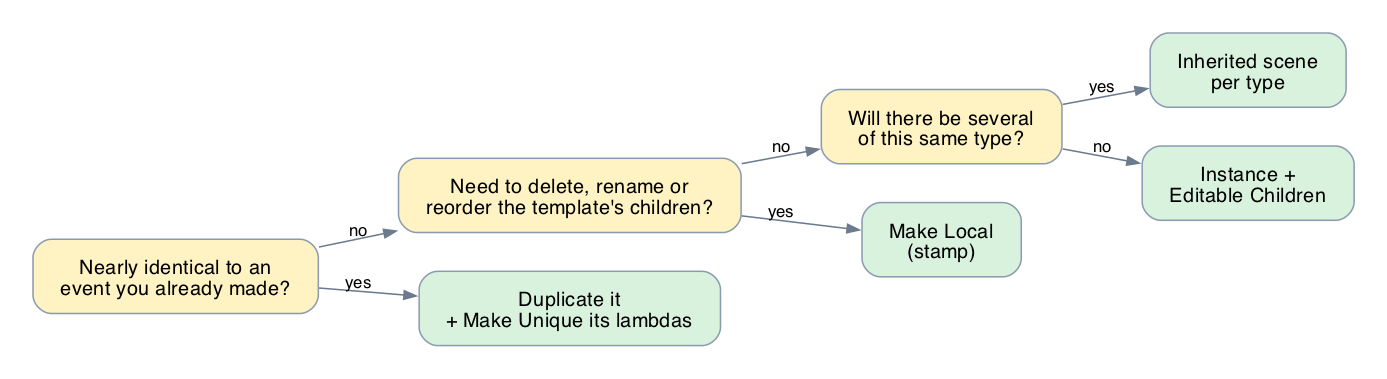

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  nodesep=0.35; ranksep=0.5;
  q0 [label="Nearly identical to an\nevent you already made?", fillcolor="#fff3c4"];
  q1 [label="Need to delete, rename or\nreorder the template's children?", fillcolor="#fff3c4"];
  q2 [label="Will there be several\nof this same type?", fillcolor="#fff3c4"];
  dup [label="Duplicate it\n+ Make Unique its lambdas", fillcolor="#d9f2dd"];
  local [label="Make Local\n(stamp)", fillcolor="#d9f2dd"];
  inh [label="Inherited scene\nper type", fillcolor="#d9f2dd"];
  edit [label="Instance +\nEditable Children", fillcolor="#d9f2dd"];
  q0 -> dup [label="yes"];
  q0 -> q1 [label="no"];
  q1 -> local [label="yes"];
  q1 -> q2 [label="no"];
  q2 -> inh [label="yes"];
  q2 -> edit [label="no"];
}
```

</details>

| If the event is... | Use |
|---|---|
| A near copy of one already on the map | Duplicate, then Make Unique its lambdas |
| A one-off whose node tree you want to reshape | Make Local |
| One of a family that should stay alike | Inherited scene for the family |
| A standard event with only values changed | Instance + Editable Children |

The "New Event" tool is not on the chart because it is not a per-event choice. It replaces the first step of Make Local once that routine becomes a chore (section 3.5).


### Feel it: the chooser as code

Change the answers, or add your own events.

In [1]:
def choose(copy_of_existing=False, reshape_tree=False, several_of_this_type=False):
	if copy_of_existing:        return "Duplicate + Make Unique its lambdas"
	if reshape_tree:            return "Make Local (stamp)"
	if several_of_this_type:    return "Inherited scene for the type"
	return "Instance + Editable Children"

events = {
	"Event 1-1 intro (message, camera jump, fade in)":  dict(reshape_tree=True),
	"A villager who only talks":                        dict(),
	"Mini-game starter (birds, mole hole, kalam)":      dict(several_of_this_type=True),
	"Second fade talker (pair of the first)":           dict(copy_of_existing=True),
	"Ghost enemy (there are three)":                    dict(several_of_this_type=True),
}
for name, answers in events.items():
	print(f"{name:<52} -> {choose(**answers)}")

Event 1-1 intro (message, camera jump, fade in)      -> Make Local (stamp)
A villager who only talks                            -> Instance + Editable Children
Mini-game starter (birds, mole hole, kalam)          -> Inherited scene for the type
Second fade talker (pair of the first)               -> Duplicate + Make Unique its lambdas
Ghost enemy (there are three)                        -> Inherited scene for the type


In [2]:
# ----- student scratchpad -----

## 2. What stays connected to what

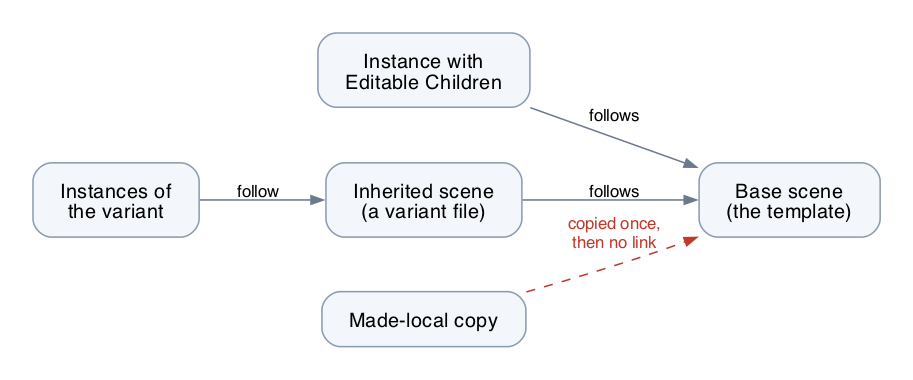

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  base [label="Base scene\n(the template)"];
  edit [label="Instance with\nEditable Children"];
  inh [label="Inherited scene\n(a variant file)"];
  inhi [label="Instances of\nthe variant"];
  local [label="Made-local copy"];
  edit -> base [label="follows"];
  inh -> base [label="follows"];
  inhi -> inh [label="follow"];
  local -> base [label="copied once,\nthen no link", style=dashed, color="#c0392b", fontcolor="#c0392b"];
}
```

</details>

| Method | Follows the base's layout | Follows the child scenes (`_rpgm_script.tscn`, portrait) | Follows the `.gd` code |
|---|---|---|---|
| Make Local | **No** | Yes | Yes |
| Editable Children | Yes | Yes | Yes |
| Inherited scene | Yes (through the variant) | Yes | Yes |
| Duplicate | Same as the event you copied | Yes | Yes |

So even a made-local event is not cut off from everything. Its script and portrait children are still instances of their own scenes, and its behaviour still lives in shared `.gd` files. The only thing it stops following is the template's top-level layout.


## 3. Each method in practice

### 3.1 Make Local (stamp)

| | |
|---|---|
| **Best when** | The event is a one-off, or you want to rename, delete or reorder its nodes |
| **Example in this game** | The "Event 1-1" intro: show a message, jump the camera, fade in. Nothing else on the map looks like it |
| **How** | 1. Drag the resource-free base onto the map. 2. Right-click it, Make Local. 3. Rename it and reshape the tree. 4. Add lambdas on its script node |
| **You gain** | The whole tree is yours. Nothing you do can show up in the base or in another event |
| **You give up** | If the template's layout improves later, this event does not get it |
| **Watch out** | Only safe from sharing if the base holds no lambdas. Stamp from the base each time; don't copy a finished event |

### 3.2 Instance + Editable Children

| | |
|---|---|
| **Best when** | The event is a standard one and only its values differ |
| **Example in this game** | `_map_4/_npc_0_1`, a talker whose portrait is switched to the "blue" sprite. The map stores just that one diff |
| **How** | 1. Drag the base onto the map. 2. Right-click it, tick Editable Children. 3. Change values on the child nodes. 4. Add extra children if needed |
| **You gain** | A fix or addition in the base reaches every event. The map file stays small and readable |
| **You give up** | You cannot delete or rename the template's children, only hide or deactivate them |
| **Watch out** | Diffs are stored by node path. Rename `_RPGM_Script` in the base and every event's diffs on it silently stop applying |

### 3.3 Inherited scene per variant

| | |
|---|---|
| **Best when** | There will be several events of one type that should stay alike |
| **Example in this game** | The three mini-game starters ("This will start the ... mini game"), or the three ghost enemies. One "mini-game starter" scene, three instances that differ only in which game they open |
| **How** | 1. Right-click the base in the FileSystem dock, New Inherited Scene. 2. Set up the type there and save it as its own file. 3. Instance that file on the map |
| **You gain** | Change the type once and all of its events follow |
| **You give up** | One more file per type, and the same no-delete limit as Editable Children |
| **Watch out** | Lambdas saved in the variant file are shared by all its instances. That is right for a line every ghost says, wrong for text that should differ per event |

### 3.4 Duplicate an existing event

| | |
|---|---|
| **Best when** | The new event is almost the same as one already placed |
| **Example in this game** | The pair of fade talkers: one fades out and switches the event to state B, the other fades in and switches back |
| **How** | 1. Select the finished event, Cmd+D. 2. On the copy, Make Unique each lambda. 3. Then edit |
| **You gain** | The fastest route when 90% is the same |
| **You give up** | Nothing structural; the copy is whatever the original was (local or instance) |
| **Watch out** | Skip step 2 and both events edit the same lambda. This is the "Lo !" bug |

### 3.5 A "New Event" tool

| | |
|---|---|
| **Best when** | The stamping routine has become a chore you repeat many times a session |
| **Example in this game** | One button that does: add an event at the cursor tile, name it by its map position, snap it to the grid (your Quantise step), and select its script node ready for lambdas |
| **How** | An `EditorPlugin` button or menu entry that builds the nodes in code, sets each node's `owner` to the scene root, and goes through undo |
| **You gain** | One click, no template to keep clean, and names and positions are always right |
| **You give up** | Time to write it, and it is one more piece of editor code to maintain |
| **Watch out** | Nodes made by a tool without an `owner` are not saved (gotcha E1 in `godot-gotchas-and-best-practices`) |


## 4. "What happens when..."

| Situation | Make Local | Editable Children | Inherited scene | Duplicate |
|---|---|---|---|---|
| You add a child to the base later | Existing events don't get it | Every event gets it | Every variant and its events get it | Depends on what you copied |
| You rename a child in the base | No effect | Diffs on that child silently detach | Diffs on that child silently detach | Depends on what you copied |
| You want to delete one of the template's children | Just delete it | Not possible; hide or deactivate it | Not possible; hide or deactivate it | Possible if the original was local |
| You fix the type's layout | Once per event, by hand | Once, in the base | Once, in the base or the variant | Once per event, by hand |
| You add a lambda afterwards | Stored in the map, owned by this event | Stored in the map, owned by this event | Stored in the map (on an instance) or shared (in the variant) | Stored in the map |
| You edit a lambda that was already there | Safe only if you made it unique | Safe only if you made it unique | Changes it for every instance of the variant | **Changes it on the original too** |
| What the map file holds | The whole event tree | A link and the diffs | A link and the diffs | The whole event tree again |
| Editing the event changes the base file | Never | Never | Never | Never |


## 5. Make Local and Editable Children, step by step

| Step | Make Local | Editable Children |
|---|---|---|
| 1 | Drag the resource-free base onto the map | Drag the resource-free base onto the map |
| 2 | Right-click, **Make Local** | Right-click, tick **Editable Children** |
| 3 | The children become ordinary nodes of the map | The children show up greyed: visible and editable, still owned by the base |
| 4 | Rename, delete, reorder, add nodes freely | Change values on the children; add new children |
| 5 | Add lambdas on the script node | Add lambdas on the script node |
| 6 | Save: the full tree is written into the map | Save: a link plus your diffs is written into the map |
| **Result** | **An independent event. Template changes stop here** | **A linked event. Template changes keep arriving** |

Step 5 is identical on purpose: because the base holds no lambdas, the ones you add are created in the map and belong to that event either way.


## 6. Rules that hold for every method

| Rule | Why |
|---|---|
| Keep the base scene free of lambdas and other per-event data | Anything saved in the template is one shared object for every event made from it |
| Start from the base, not from a finished event | A finished event carries lambdas, and copies share them |
| Make Unique before editing anything that came from a template or a copy | Nodes are copied; resources are not |
| The portrait's animations and materials are shared by all events | Fine for animation data. Before tweaking a material on one event, Make Unique it |
| Keep child names stable in the base | Editable Children and inherited scenes find their diffs by node path |
| Editing a placed event never changes the base file | Only saving the base scene itself does. If the base tab looks changed, reload it; don't save it |


## 7. How is my map built today?

Reads `_rpgm_map.tscn` (read-only) and counts how events got there.


In [3]:
import os, re
from collections import Counter

root = os.getcwd()
while not os.path.exists(os.path.join(root, "project.godot")) and root != "/":
	root = os.path.dirname(root)

text = open(os.path.join(root, "viewports/rpgm/_rpgm_map.tscn"), errors="ignore").read()

scenes = {m.group(2): m.group(1) for m in re.finditer(r'\[ext_resource type="PackedScene"[^\]]*path="([^"]*)" id="([^"]*)"\]', text)}
editable = set(re.findall(r'\[editable path="([^"]*)"\]', text))

nodes = []
for header in re.findall(r'^\[node ([^\]]*)\]', text, re.M):
	attrs = dict(re.findall(r'(\w+)="([^"]*)"', header))
	inst = re.search(r'instance=ExtResource\("([^"]*)"\)', header)
	parent = attrs.get("parent", "")
	path = attrs["name"] if parent in ("", ".") else parent + "/" + attrs["name"]
	nodes.append(dict(path=path, parent=parent, scene=scenes.get(inst.group(1)) if inst else None, typed="type" in attrs))

templates = Counter(os.path.basename(n["scene"]) for n in nodes if n["scene"] and "/common_events/" in n["scene"])
with_editable = Counter(os.path.basename(n["scene"]) for n in nodes if n["scene"] and "/common_events/" in n["scene"] and n["path"] in editable)
local = sorted({n["parent"] for n in nodes if n["scene"] and n["scene"].endswith("_rpgm_script.tscn")})
diffs = [n for n in nodes if not n["scene"] and not n["typed"]]

print(f"{'template scene':<42}{'instances':>10}{'with Editable Children':>25}")
for name, count in templates.most_common():
	print(f"{name:<42}{count:>10}{with_editable[name]:>25}")

print(f"\nmade-local or hand-built events (they own a script instance): {len(local)}")
for path in local: print("   ", path)

print(f"\nchild diffs stored for Editable Children: {len(diffs)}")
for n in diffs: print("   ", n["path"])

template scene                             instances   with Editable Children
_common_talker_v2.tscn                             4                        1
_common_teleport_v1.tscn                           2                        0
_common_player_position_v1.tscn                    2                        0
_common_camera_position_v1.tscn                    1                        0
_common_base_0_0_no_resource.tscn                  1                        0

made-local or hand-built events (they own a script instance): 2
    _common_base_0_0
    _common_base_0_0_no_resource

child diffs stored for Editable Children: 2
    _map_4/_npc_0_1/_common_script_talker_1
    _map_4/_npc_0_1/_common_script_talker_1/_RPGM_Portrait


In [4]:
# ----- student scratchpad -----

| Line in the output | Method it shows |
|---|---|
| A template with instances, 0 with Editable Children | Plain instances: placed and left as they are |
| A template "with Editable Children" | Section 3.2 in use; the child diffs are listed at the bottom |
| Made-local or hand-built events | Section 3.1 in use |

The scripts embedded in the map (the older events) are not counted here; this only sees events built from scenes.
